# TP Jour 4 — Tests d'Hypothèses Statistiques, Segmentation & Restitution BI

### Objectifs de la séance
1. Valider scientifiquement deux hypothèses métier sur votre dataset à l'aide de **tests statistiques adaptés** (`scipy.stats`).
2. Construire une **segmentation / typologie non supervisée (K-Means)** combinant agrégation distribuée **PySpark**, transformation d'asymétrie (`log1p`), standardisation (`StandardScaler`) et labellisation métier vers **`/lakehouse/gold/`**.
3. Développer votre **Dashboard Streamlit interactif** dans `app/dashboard.py` (`http://localhost:8501`) en documentant chaque requête SQL et chaque choix statistique.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("J4_Stats_Segmentation_Dashboard")
    .getOrCreate()
)

## 1. Inférence Statistique : Tester vos Hypothèses Métier (`scipy.stats`)

Choisissez **au moins deux tests statistiques** pertinents pour votre sujet parmi :
- **Comparaison de 2 groupes indépendants** sur une variable asymétrique : **Mann-Whitney U** (`stats.mannwhitneyu`).
- **Comparaison de $k \ge 3$ groupes** : **Kruskal-Wallis** (`stats.kruskal`).
- **Lien monotone entre 2 variables quantitatives** non gaussiennes : **Corrélation de rangs de Spearman** (`stats.spearmanr`).
- **Dépendance entre 2 variables qualitatives** : **Test du $\chi^2$** (`stats.chi2_contingency`).

### Exercice 1.1 — Formuler $H_0 / H_1$, projeter les colonnes utiles depuis Silver et conclure
> **Bonne pratique Big Data :** Ne faites jamais `.toPandas()` sur toute une table Silver brute ! Filtrez et sélectionnez (`select(...)`) uniquement les colonnes nécessaires côté PySpark avant de rapatrier les données vers le driver.

**Formulation de vos hypothèses  :**
- **Test #1 — Mann-Whitney :** H₀ = les distributions des retards à l’arrivée sont identiques pour les deux aéroports comparés ; H₁ = elles diffèrent. Ce test non paramétrique convient à la comparaison de deux groupes indépendants lorsque les données peuvent être asymétriques.
- **Test #2 — Spearman :** H₀ = il n’existe pas d’association monotone entre la distance du vol et son retard à l’arrivée ; H₁ = il en existe une. Cette corrélation de rangs ne suppose pas une distribution normale.
- **Test #3 — Kruskal-Wallis :** H₀ = le retard à l'arrivée a la même distribution pour toutes les compagnies ; H₁ = au moins une compagnie diffère. On compare 14 groupes sur une variable très asymétrique (skewness ≈ 6,5 en J3) : Kruskal-Wallis est l'équivalent non paramétrique de l'ANOVA.

Avec des dizaines de milliers de vols, la moindre différence devient « significative ». Pour chaque test, on donne donc aussi une **taille d'effet** (r pour Mann-Whitney, ρ pour Spearman, ε² pour Kruskal-Wallis) qui dit si l'écart compte en pratique.

In [2]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"
silver_df = spark.read.format("delta").load(SILVER_MAIN_PATH)

# Comparer les retards des deux aéroports avec le plus de vols.
top_airports = [
    row["origin_airport"]
    for row in (
        silver_df
        .groupBy("origin_airport")
        .count()
        .orderBy(F.desc("count"), F.asc("origin_airport"))
        .limit(2)
        .collect()
    )
]
assert len(top_airports) == 2, "Il faut au moins deux aéroports dans la table Silver."

# Échantillons aléatoires limités pour ne pas rapatrier toute la table.
groups = []
for airport in top_airports:
    sample_pd = (
        silver_df
        .where(
            (F.col("origin_airport") == airport)
            & F.col("arrival_delay").isNotNull()
        )
        .select("origin_airport", "arrival_delay")
        .sample(withReplacement=False, fraction=0.2, seed=42)
        .limit(20_000)
        .toPandas()
    )
    groups.append(sample_pd)

df_sample = pd.concat(groups, ignore_index=True)

group_a = df_sample.loc[
    df_sample["origin_airport"] == top_airports[0], "arrival_delay"
].dropna()
group_b = df_sample.loc[
    df_sample["origin_airport"] == top_airports[1], "arrival_delay"
].dropna()

assert len(group_a) >= 2 and len(group_b) >= 2, (
    "Échantillon insuffisant pour le test de Mann-Whitney."
)

stat_1, p_val_1 = stats.mannwhitneyu(
    group_a, group_b, alternative="two-sided"
)

print(f"Test de Mann-Whitney : {top_airports[0]} contre {top_airports[1]}")
print(f"Médianes des retards : {group_a.median():.2f} et {group_b.median():.2f} minutes")
print(f"U = {stat_1:.2f} ; p-value = {p_val_1:.4g}")
print(
    "Conclusion :",
    "les distributions diffèrent significativement (seuil 5 %)."
    if p_val_1 < 0.05
    else "pas de différence significative détectée (seuil 5 %)."
)

# Tester la corrélation entre distance et retard sur un échantillon limité.
spearman_pd = (
    silver_df
    .select("distance", "arrival_delay")
    .where(
        F.col("distance").isNotNull()
        & F.col("arrival_delay").isNotNull()
    )
    .sample(withReplacement=False, fraction=0.05, seed=42)
    .limit(30_000)
    .toPandas()
    .dropna()
)

assert len(spearman_pd) >= 3, "Échantillon insuffisant pour le test de Spearman."

rho, p_val_2 = stats.spearmanr(
    spearman_pd["distance"], spearman_pd["arrival_delay"]
)

print("\nTest de Spearman : distance et retard à l'arrivée")
print(f"rho = {rho:.4f} ; p-value = {p_val_2:.4g}")
print(
    "Conclusion :",
    "association monotone significative (seuil 5 %)."
    if p_val_2 < 0.05
    else "pas d'association monotone significative détectée (seuil 5 %)."
)

# Taille d'effet de Mann-Whitney : r = |Z| / sqrt(n), avec Z issu de l'approximation normale de U
n1, n2 = len(group_a), len(group_b)
z_1 = (stat_1 - n1 * n2 / 2) / np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
effet_1 = abs(z_1) / np.sqrt(n1 + n2)
print(f"\nTaille d'effet Mann-Whitney : r = {effet_1:.3f} (n = {n1 + n2:,})")
print(f"Taille d'effet Spearman : |rho| = {abs(rho):.3f}, soit {100 * rho**2:.2f} % de variance des rangs partagée (n = {len(spearman_pd):,})")

Test de Mann-Whitney : ATL contre ORD
Médianes des retards : -5.00 et -5.00 minutes
U = 4762467.50 ; p-value = 0.3193
Conclusion : pas de différence significative détectée (seuil 5 %).



Test de Spearman : distance et retard à l'arrivée
rho = -0.0752 ; p-value = 2.056e-19
Conclusion : association monotone significative (seuil 5 %).

Taille d'effet Mann-Whitney : r = 0.013 (n = 6,252)
Taille d'effet Spearman : |rho| = 0.075, soit 0.57 % de variance des rangs partagée (n = 14,301)


In [3]:
# Test #3 : Kruskal-Wallis sur le retard à l'arrivée entre les 14 compagnies.
# On ne rapatrie que deux colonnes des vols arrivés (environ 285 000 lignes, quelques Mo).
kw_pd = (
    silver_df
    .where(F.col("arrival_delay").isNotNull() & F.col("airline").isNotNull())
    .select("airline", "airline_name", "arrival_delay")
    .toPandas()
)
groupes_kw = [g["arrival_delay"].to_numpy() for _, g in kw_pd.groupby("airline")]
stat_3, p_val_3 = stats.kruskal(*groupes_kw)
n_kw, k_kw = len(kw_pd), len(groupes_kw)
effet_3 = (stat_3 - k_kw + 1) / (n_kw - k_kw)  # epsilon² (part de la variance des rangs expliquée par la compagnie)

print(f"Test de Kruskal-Wallis : {k_kw} compagnies, n = {n_kw:,}")
print(f"H = {stat_3:,.1f} ; p-value = {p_val_3:.3g} ; epsilon² = {effet_3:.4f}")
medianes = kw_pd.groupby("airline_name")["arrival_delay"].agg(
    mediane="median", taux_retard_15=lambda s: round(100 * (s >= 15).mean(), 1), n="size"
).sort_values("taux_retard_15")
print(medianes.to_string())

Test de Kruskal-Wallis : 14 compagnies, n = 285,730
H = 3,523.5 ; p-value = 0 ; epsilon² = 0.0123
                              mediane  taux_retard_15      n
airline_name                                                
Hawaiian Airlines Inc.           -2.0            12.5   3774
Alaska Airlines Inc.             -6.0            13.5   8634
Delta Air Lines Inc.             -8.0            13.6  43316
American Airlines Inc.           -6.0            18.0  35872
Skywest Airlines Inc.            -4.0            18.7  28845
Virgin America                   -4.0            19.1   3119
Southwest Airlines Co.           -4.0            19.2  62195
Atlantic Southeast Airlines      -4.0            19.4  27927
US Airways Inc.                  -4.0            19.5   9778
United Air Lines Inc.            -6.0            20.9  25115
American Eagle Airlines Inc.     -6.0            22.0  13820
JetBlue Airways                  -5.0            22.4  13114
Frontier Airlines Inc.           -2.0           

**Conclusions des tests**

- **Mann-Whitney, Atlanta contre Chicago O'Hare : on ne rejette pas H₀** (p = 0,32, r = 0,01). Les deux aéroports ont la même médiane (−5 min) et la même distribution d'ensemble. Pourtant, en J3, O'Hare a 24 % de vols en retard contre 17 % à Atlanta. Les deux résultats sont compatibles : la différence se joue dans la queue de la distribution (les retards de plus de 15 minutes), pas sur le vol typique, qui arrive en avance dans les deux cas. C'est pourquoi on suit le taux de retard en plus de la médiane.
- **Spearman, distance et retard : H₀ rejetée, mais l'effet est quasi nul** (ρ = −0,075, p ≈ 2·10⁻¹⁹). La distance n'explique que 0,6 % de la variance des rangs du retard. Le léger signe négatif s'explique : sur un long vol, l'équipage peut rattraper une partie du retard au départ. Pour un voyageur, la distance n'est pas un facteur de risque.
- **Kruskal-Wallis, entre compagnies : H₀ rejetée** (H = 3 524, p < 10⁻³⁰⁰), mais avec une taille d'effet faible (ε² = 0,012). La compagnie n'explique qu'environ 1 % de la variance des rangs : le retard d'un vol donné dépend d'abord d'autres facteurs (heure de départ, météo, propagation des retards). L'écart reste pourtant concret pour un voyageur : de 12,5 % de vols en retard chez Hawaiian à 30 % chez Spirit.
- **Leçon générale** : avec des dizaines de milliers de vols, presque tout devient « significatif ». La taille d'effet est indispensable pour distinguer un écart réel mais négligeable (distance) d'un écart qui compte en pratique (compagnie).

In [4]:
# Table Gold des tests, lue par l'onglet « Ce qu'il faut retenir » du dashboard
tests_pd = pd.DataFrame([
    {"test": "Mann-Whitney U", "question": f"Le retard diffère-t-il entre {top_airports[0]} et {top_airports[1]} ?",
     "h0": "Même distribution du retard dans les deux aéroports", "statistique": float(stat_1), "p_value": float(p_val_1),
     "taille_effet": float(effet_1), "mesure_effet": "r", "h0_rejetee": bool(p_val_1 < 0.05)},
    {"test": "Spearman", "question": "Les vols longs sont-ils plus en retard ?",
     "h0": "Pas de lien monotone entre distance et retard", "statistique": float(rho), "p_value": float(p_val_2),
     "taille_effet": float(abs(rho)), "mesure_effet": "|rho|", "h0_rejetee": bool(p_val_2 < 0.05)},
    {"test": "Kruskal-Wallis", "question": "Les compagnies ont-elles le même retard ?",
     "h0": "Même distribution du retard pour toutes les compagnies", "statistique": float(stat_3), "p_value": float(p_val_3),
     "taille_effet": float(effet_3), "mesure_effet": "epsilon²", "h0_rejetee": bool(p_val_3 < 0.05)},
])
tests_pd["conclusion"] = [
    "Pas de différence significative entre ATL et ORD (p = 0,32, médianes identiques à -5 min). L'écart de taux de retard vu en J3 vient de la queue de la distribution.",
    "Lien significatif mais quasi nul (rho = -0,075) : la distance n'explique pas le retard.",
    "Les compagnies diffèrent (p < 0,001) mais l'effet est faible (epsilon² = 0,012) ; le taux de retard va pourtant de 12,5 % (Hawaiian) à 30 % (Spirit).",
]
(spark.createDataFrame(tests_pd).coalesce(1).write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true").save("/lakehouse/gold/stats_tests"))
tests_pd[["test", "statistique", "p_value", "taille_effet", "h0_rejetee"]]

,test,statistique,p_value,taille_effet,h0_rejetee
0,Mann-Whitney U,4.762468e+06,3.193427e-01,0.012591,False
1,Spearman,-7.524446e-02,2.056219e-19,0.075244,True
2,Kruskal-Wallis,3.523470e+03,0.000000e+00,0.012287,True


## 2. Segmentation / Typologie par Clustering K-Means (`/lakehouse/gold/`)

Quelle que soit la thématique de votre dataset Kaggle, identifiez l'**entité métier pertinente à segmenter** (ex. clients/utilisateurs, stations, zones géographiques, produits, lignes de transport, capteurs...) :
1. **Agrégation PySpark** : résumez chaque entité par **3 à 5 features numériques comportementales** (fréquence, volume, valeur médiane/totale, récence, taux d'incident...).
2. **Prétraitement statistique** : appliquez `np.log1p(...)` sur les features positives asymétriques puis centrez-réduisez avec `StandardScaler()` afin qu'aucune variable à grande échelle n'écrase la distance euclidienne du K-Means.
3. **Interprétation métier** : inspectez les médianes par cluster (`groupby("cluster_id").median()`), attribuez un **nom explicite** à chaque segment (`colonne "segment"`), puis enregistrez la table dans **`/lakehouse/gold/<nom_table_segments>`**.

**Corrections par rapport à la première version**
- Octobre est exclu (`airport_code_valid`) : ses codes aéroport numériques créaient environ 290 faux aéroports.
- On ne garde que les aéroports avec au moins 300 vols (même seuil que l'ACP de J2) : en dessous, les taux reposent sur trop peu de vols et le K-Means regroupait surtout de petits échantillons.
- La médiane du retard positif valait 0 pour tous les aéroports (plus de la moitié des vols arrivent à l'heure partout) : elle est remplacée par le **P90 du retard**, qui mesure les gros retards.
- Le nombre de groupes k est choisi avec la méthode du coude, le score silhouette et l'indice de Davies-Bouldin.

104 aéroports avec au moins 300 vols
Asymétrie des variables : {'nb_vols': 2.48, 'retard_p90_min': 0.18, 'taux_retard_15': -0.06, 'taux_annulation': 0.92, 'distance_mediane': 0.93}


 k  inertie  silhouette  davies_bouldin
 2  368.874       0.280           1.353
 3  291.024       0.268           1.160
 4  239.575       0.272           1.083
 5  204.294       0.268           1.114
 6  174.957       0.261           1.081
 7  153.080       0.246           1.142
 8  138.776       0.257           1.060


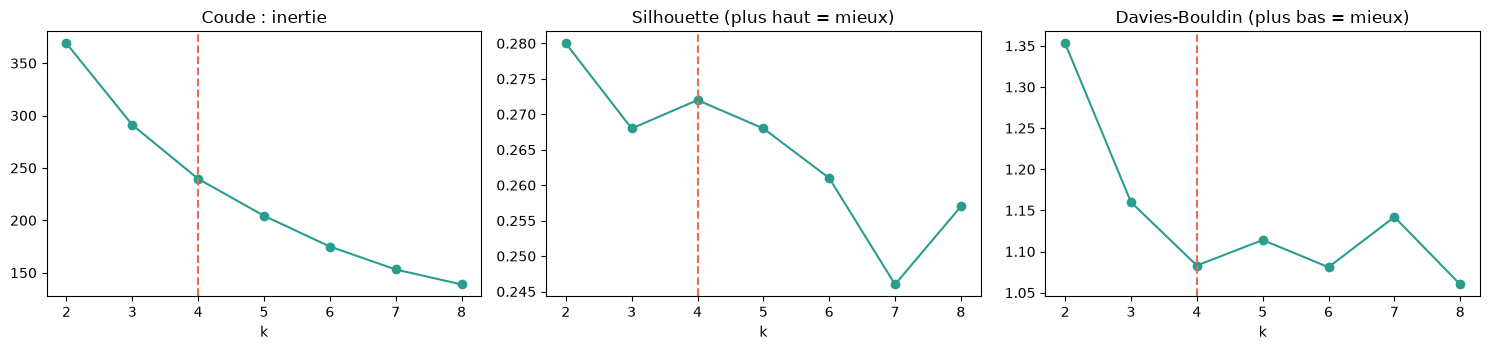

In [5]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"
GOLD_SEGMENTS_PATH = "/lakehouse/gold/segments_aeroports"

silver_df = spark.read.format("delta").load(SILVER_MAIN_PATH)

# Résumer les vols par aéroport côté Spark, avant de transférer ce petit tableau vers Pandas.
entities_sdf = (
    silver_df
    .where(F.col("airport_code_valid"))
    .groupBy("origin_airport")
    .agg(
        F.first("origin_city").alias("origin_city"),
        F.first("origin_state").alias("origin_state"),
        F.first("origin_lat").alias("origin_lat"),
        F.first("origin_lon").alias("origin_lon"),
        F.count("*").alias("nb_vols"),
        F.percentile_approx("arrival_delay", 0.9).alias("retard_p90_min"),
        F.avg(
            F.when(
                F.col("arrival_delay").isNotNull(),
                (F.col("arrival_delay") >= 15).cast("double")
            )
        ).alias("taux_retard_15"),
        F.avg(
            F.coalesce(F.col("is_cancelled").cast("double"), F.lit(0.0))
        ).alias("taux_annulation"),
        F.percentile_approx("distance", 0.5).alias("distance_mediane")
    )
    .where(F.col("nb_vols") >= 300)
)

entities_pd = entities_sdf.toPandas().dropna().copy()
feature_cols = ["nb_vols", "retard_p90_min", "taux_retard_15", "taux_annulation", "distance_mediane"]
print(f"{len(entities_pd)} aéroports avec au moins 300 vols")
print("Asymétrie des variables :", entities_pd[feature_cols].skew().round(2).to_dict())

# log1p sur les variables positives et asymétriques (trafic, distance), puis centrage-réduction
features = entities_pd[feature_cols].copy()
for col in ["nb_vols", "distance_mediane"]:
    features[col] = np.log1p(features[col].clip(lower=0))
X = StandardScaler().fit_transform(features)

# Choix de k : coude (inertie), silhouette (plus haut = mieux), Davies-Bouldin (plus bas = mieux)
ks = range(2, 9)
scores = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X)
    scores.append((k, km.inertia_, silhouette_score(X, km.labels_), davies_bouldin_score(X, km.labels_)))
scores = pd.DataFrame(scores, columns=["k", "inertie", "silhouette", "davies_bouldin"]).round(3)
print(scores.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, titre in zip(axes, ["inertie", "silhouette", "davies_bouldin"],
                          ["Coude : inertie", "Silhouette (plus haut = mieux)", "Davies-Bouldin (plus bas = mieux)"]):
    ax.plot(scores["k"], scores[col], "o-", color="#2A9D8F")
    ax.axvline(4, ls="--", color="#E76F51")
    ax.set_title(titre)
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

**Choix de k**

- **Le coude n'est pas net** : l'inertie baisse régulièrement de k = 2 à k = 8, ce qui est attendu pour des aéroports dont les profils varient de façon continue.
- **La silhouette reste stable autour de 0,27** entre k = 2 et k = 5 (structure modérée), puis baisse.
- **L'indice de Davies-Bouldin baisse nettement jusqu'à k = 4 (1,08)** puis remonte à k = 5. Il est à peine plus bas à k = 8 (1,06), mais avec des groupes trop petits pour être interprétés.
- On retient donc **k = 4** : c'est le meilleur compromis entre la qualité des groupes et leur interprétation métier.

In [6]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=20)
entities_pd["cluster_id"] = kmeans.fit_predict(X).astype(int)

# Examiner les profils pour interpréter les groupes.
profile = entities_pd.groupby("cluster_id")[feature_cols].median()
profile["nb_aeroports"] = entities_pd.groupby("cluster_id").size()
display(profile.round(3))

# Nommer les groupes à partir de leur profil (règles indépendantes du numéro de cluster)
reste = list(profile.index)
hubs = profile.loc[reste, "nb_vols"].idxmax(); reste.remove(hubs)
courts = profile.loc[reste, "distance_mediane"].idxmin(); reste.remove(courts)
perturbes = profile.loc[reste, "taux_annulation"].idxmax(); reste.remove(perturbes)
label_map = {
    hubs: "Grands hubs congestionnés",
    courts: "Vols courts et ponctuels",
    perturbes: "Aéroports régionaux perturbés",
    reste[0]: "Aéroports fiables",
}
entities_pd["segment"] = entities_pd["cluster_id"].map(label_map)

for seg, g in entities_pd.groupby("segment"):
    print(f"{seg} ({len(g)}) : {', '.join(g.nlargest(8, 'nb_vols')['origin_airport'])}")

assert "segment" in entities_pd.columns

(
    spark.createDataFrame(entities_pd)
    .coalesce(2)
    .write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(GOLD_SEGMENTS_PATH)
)

print(
    f"Table de segmentation enregistrée dans {GOLD_SEGMENTS_PATH} "
    f"({len(entities_pd):,} aéroports)"
)

,nb_vols,retard_p90_min,taux_retard_15,taux_annulation,distance_mediane,nb_aeroports
cluster_id,,,,,,
0,1324.5,29.0,0.166,0.011,608.0,40
1,410.5,35.5,0.188,0.025,482.5,34
2,4495.5,39.0,0.215,0.017,853.5,26
3,778.5,17.5,0.126,0.003,182.0,4


Aéroports fiables (40) : ATL, PHX, MSP, SEA, DTW, SLC, SAN, TPA
Aéroports régionaux perturbés (34) : RDU, CMH, CVG, ONT, OKC, MEM, RIC, TUL
Grands hubs congestionnés (26) : ORD, DFW, LAX, DEN, IAH, SFO, LAS, MCO
Vols courts et ponctuels (4) : HNL, OGG, LIH, KOA


Table de segmentation enregistrée dans /lakehouse/gold/segments_aeroports (104 aéroports)


**Interprétation des segments**

| Segment | Aéroports | Profil (médianes) |
|---|---|---|
| **Grands hubs congestionnés** (26) | ORD, DFW, LAX, DEN, IAH, SFO, LAS, MCO | le plus de trafic (4 500 vols), vols longs (850 miles), 21,5 % de retard, P90 de 39 min |
| **Aéroports régionaux perturbés** (34) | RDU, CMH, CVG, ONT, OKC, MEM, RIC, TUL | peu de trafic (410 vols), le plus d'annulations (2,5 %), 18,8 % de retard |
| **Aéroports fiables** (40) | ATL, PHX, MSP, SEA, DTW, SLC, SAN, TPA | trafic moyen à fort, 16,6 % de retard, 1,1 % d'annulations |
| **Vols courts et ponctuels** (4) | HNL, OGG, LIH, KOA (Hawaï) | vols de 180 miles, 12,6 % de retard, P90 de 17 min, presque aucune annulation |

- Les deux premiers segments retrouvent les deux axes de l'ACP de J2 : la congestion des grands hubs (axe 1) et les perturbations ponctuelles des petits aéroports (axe 2).
- **Atlanta, le plus gros aéroport du pays, est classé parmi les aéroports fiables** : la taille seule ne fait pas le retard, comme l'EDA de J2 l'avait déjà montré.
- Pour le voyageur : les correspondances dans les grands hubs congestionnés sont les plus risquées, et les petits aéroports régionaux exposent surtout au risque d'annulation.

## 3. Livrable Final : Votre Application `app/dashboard.py` sur Streamlit (`:8501`)

Complétez maintenant **`app/dashboard.py`** pour valoriser vos tables `/lakehouse/gold/` :
- **Architecture respectée** : l'application Streamlit ne doit lire **que** des tables pré-calculées de la couche **Gold** (`/lakehouse/gold/...`), jamais les fichiers CSV bruts !
- **Interactivité** : au moins un filtre utilisateur (`st.selectbox`, `st.multiselect`, `st.slider`) et 3 à 4 visualisations Plotly Express complémentaires.
- **Rigueur explicative** : sous chaque visualisation clé, intégrez un `st.expander("Requête SQL & Justification statistique")` affichant la requête Spark SQL ayant produit la table Gold et justifiant le choix des indicateurs statistiques retenus.

In [7]:
# Vérification finale de l'inventaire complet de votre couche Gold sur HDFS
jvm = spark._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = jvm.org.apache.hadoop.fs.Path
gold_root = PathHDFS("/lakehouse/gold")

gold_tables = [
    s.getPath().getName()
    for s in fs.listStatus(gold_root)
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log"))
]
assert len(gold_tables) > 0, "Aucune table Delta trouvée dans /lakehouse/gold/ !"

print("=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===")
for t in sorted(gold_tables):
    cnt = spark.read.format("delta").load(f"/lakehouse/gold/{t}").count()
    print(f" - /lakehouse/gold/{t:<25} : {cnt:>9,} lignes")

=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===


 - /lakehouse/gold/flight_replay             :     3,312 lignes


 - /lakehouse/gold/kpi_airline_worst_airport :        14 lignes


 - /lakehouse/gold/kpi_airlines              :        14 lignes


 - /lakehouse/gold/kpi_airports_pareto       :       322 lignes


 - /lakehouse/gold/kpi_daily                 :       365 lignes


... (2 outputs left out)

 - /lakehouse/gold/route_flows               :     3,754 lignes


 - /lakehouse/gold/segments_aeroports        :       104 lignes


 - /lakehouse/gold/stats_tests               :         3 lignes


 - /lakehouse/gold/top_compagnie_retards_par_aeroport :       103 lignes
